# Real Madrid in La Liga, 2015–2026: What Wins Matches?

**Questions**
1. How has Real Madrid performed season by season, at home and away?
2. Which in-game statistics separate Real Madrid wins from draws and losses?
3. Do bookmakers price Real Madrid accurately, or does the team over- or under-perform market expectations?

**Data:** every La Liga match from 2015-16 through 2025-26 (11 seasons, 4,180 matches, 418 involving Real Madrid), from [football-data.co.uk](https://www.football-data.co.uk/spainm.php): final and half-time scores, shots, shots on target, corners, fouls, cards, and Bet365 pre-match odds.

**Tools:** Python, pandas, matplotlib, scikit-learn, statsmodels.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from pathlib import Path

NAVY, GOLD, GREY, PURPLE = "#1B2A49", "#C9A227", "#B8BCC6", "#6C4F9E"
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

liga = pd.read_csv("data/laliga_matches_2015_2026.csv")
liga["Date"] = pd.to_datetime(liga["Date"], dayfirst=True, format="mixed")
print(liga.shape)
print(liga["Season"].value_counts().sort_index().to_string())
print("missing values:", int(liga.isna().sum().sum()))

(4180, 24)
Season
2015-16    380
2016-17    380
2017-18    380
2018-19    380
2019-20    380
2020-21    380
2021-22    380
2022-23    380
2023-24    380
2024-25    380
2025-26    380
missing values: 0


Each row is one match. `FTHG`/`FTAG` are full-time goals for the home and away team, `HS`/`AS` shots, `HST`/`AST` shots on target, `HC`/`AC` corners, `HF`/`AF` fouls, `HY`/`AY` yellow cards, `HR`/`AR` red cards, and `B365H`/`B365D`/`B365A` Bet365's decimal odds for a home win, draw and away win.

Next I reshape the data so every match appears **from Real Madrid's point of view**: goals for and against, shots for and against, and whether they played at home.

In [2]:
TEAM = "Real Madrid"

def team_view(df, team):
    home = df[df.HomeTeam == team].assign(home=1, opponent=lambda d: d.AwayTeam,
        gf=lambda d: d.FTHG, ga=lambda d: d.FTAG, shots=lambda d: d.HS, shots_ag=lambda d: d.AS,
        sot=lambda d: d.HST, sot_ag=lambda d: d.AST, corners=lambda d: d.HC, corners_ag=lambda d: d.AC,
        fouls=lambda d: d.HF, yellows=lambda d: d.HY, reds=lambda d: d.HR, reds_opp=lambda d: d.AR,
        ht_gf=lambda d: d.HTHG, ht_ga=lambda d: d.HTAG,
        odds_win=lambda d: d.B365H, odds_draw=lambda d: d.B365D, odds_loss=lambda d: d.B365A)
    away = df[df.AwayTeam == team].assign(home=0, opponent=lambda d: d.HomeTeam,
        gf=lambda d: d.FTAG, ga=lambda d: d.FTHG, shots=lambda d: d.AS, shots_ag=lambda d: d.HS,
        sot=lambda d: d.AST, sot_ag=lambda d: d.HST, corners=lambda d: d.AC, corners_ag=lambda d: d.HC,
        fouls=lambda d: d.AF, yellows=lambda d: d.AY, reds=lambda d: d.AR, reds_opp=lambda d: d.HR,
        ht_gf=lambda d: d.HTAG, ht_ga=lambda d: d.HTHG,
        odds_win=lambda d: d.B365A, odds_draw=lambda d: d.B365D, odds_loss=lambda d: d.B365H)
    cols = ["Season", "Date", "opponent", "home", "gf", "ga", "ht_gf", "ht_ga", "shots", "shots_ag", "sot", "sot_ag",
            "corners", "corners_ag", "fouls", "yellows", "reds", "reds_opp", "odds_win", "odds_draw", "odds_loss"]
    out = pd.concat([home, away])[cols].sort_values("Date").reset_index(drop=True)
    out["result"] = np.select([out.gf > out.ga, out.gf == out.ga], ["W", "D"], "L")
    out["points"] = out.result.map({"W": 3, "D": 1, "L": 0})
    out["win"] = (out.result == "W").astype(int)
    return out

rm = team_view(liga, TEAM)
print(rm.shape)
rm.head()

(418, 24)


,Season,Date,opponent,home,gf,ga,ht_gf,ht_ga,shots,shots_ag,...,fouls,yellows,reds,reds_opp,odds_win,odds_draw,odds_loss,result,points,win
0,2015-16,2015-08-23,Sp Gijon,0,0,0,0,0,27,6,...,4,0,0,0,1.22,6.5,13.00,D,1,0
1,2015-16,2015-08-29,Betis,1,5,0,2,0,21,7,...,12,3,0,0,1.10,10.0,26.00,W,3,1
2,2015-16,2015-09-12,Espanol,0,6,0,4,0,15,14,...,10,2,0,0,1.33,5.0,10.00,W,3,1
3,2015-16,2015-09-19,Granada,1,1,0,0,0,20,12,...,9,1,0,0,1.06,15.0,26.00,W,3,1
4,2015-16,2015-09-23,Ath Bilbao,0,2,1,1,0,22,11,...,10,3,0,0,1.62,4.2,5.25,W,3,1


## 2. Season-by-season performance

In [3]:
def league_table(season_df):
    teams = pd.unique(season_df[["HomeTeam", "AwayTeam"]].values.ravel())
    rows = []
    for tm in teams:
        v = team_view(season_df, tm)
        rows.append({"team": tm, "points": v.points.sum(), "gd": (v.gf - v.ga).sum(), "gf": v.gf.sum()})
    tab = pd.DataFrame(rows).sort_values(["points", "gd", "gf"], ascending=False).reset_index(drop=True)
    tab["rank"] = tab.index + 1
    return tab

tables = {s: league_table(g) for s, g in liga.groupby("Season")}
season = rm.groupby("Season").agg(played=("result", "size"), wins=("win", "sum"),
                                  draws=("result", lambda r: (r == "D").sum()),
                                  losses=("result", lambda r: (r == "L").sum()),
                                  points=("points", "sum"), goals_for=("gf", "sum"), goals_against=("ga", "sum"))
season["goal_diff"] = season.goals_for - season.goals_against
season["finish"] = [int(tables[s].loc[tables[s].team == TEAM, "rank"].iloc[0]) for s in season.index]
season["champion"] = [tables[s].team.iloc[0] for s in season.index]
season

,played,wins,draws,losses,points,goals_for,goals_against,goal_diff,finish,champion
Season,,,,,,,,,,
2015-16,38,28,6,4,90,110,34,76,2,Barcelona
2016-17,38,29,6,3,93,106,41,65,1,Real Madrid
2017-18,38,22,10,6,76,94,44,50,3,Barcelona
2018-19,38,21,5,12,68,63,46,17,3,Barcelona
2019-20,38,26,9,3,87,70,25,45,1,Real Madrid
2020-21,38,25,9,4,84,67,28,39,2,Ath Madrid
2021-22,38,26,8,4,86,80,31,49,1,Real Madrid
2022-23,38,24,6,8,78,75,36,39,2,Barcelona
2023-24,38,29,8,1,95,87,26,61,1,Real Madrid


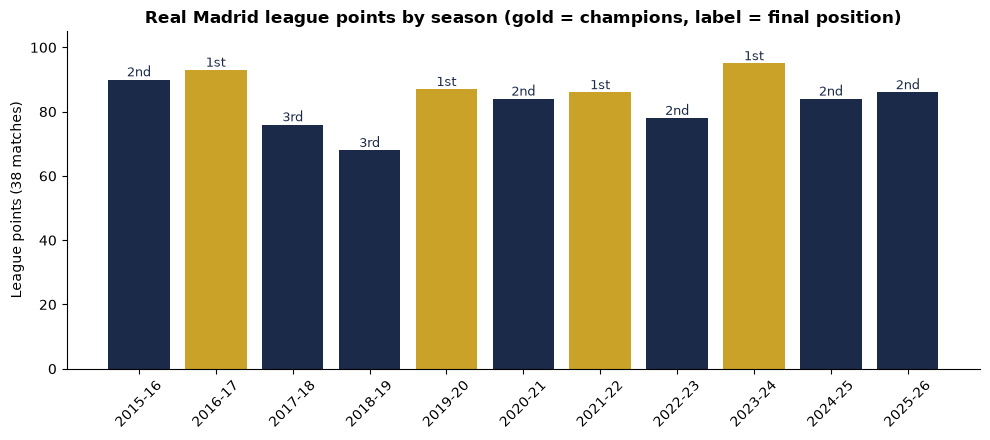

In [4]:
fig, ax = plt.subplots()
colors = [GOLD if f == 1 else NAVY for f in season.finish]
bars = ax.bar(season.index, season.points, color=colors)
for b, f in zip(bars, season.finish):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{f}{'st' if f == 1 else 'nd' if f == 2 else 'rd' if f == 3 else 'th'}",
            ha="center", fontsize=9, color=NAVY)
ax.set_ylim(0, 105)
ax.set_ylabel("League points (38 matches)")
ax.set_title("Real Madrid league points by season (gold = champions, label = final position)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/points_by_season.svg")
plt.show()

Real Madrid won La Liga **4 times in 11 seasons** (2016-17, 2019-20, 2021-22, 2023-24), finished 2nd five times and 3rd twice. They never dropped below 3rd.

- **Best season: 2023-24**, with 95 points, 29 wins and only **1 loss** all season, plus the fewest goals conceded in the span (26).
- **Worst season: 2018-19**, with 68 points and 12 losses, the only season with more than 8 defeats. That was the first season after Cristiano Ronaldo left and the club went through three head coaches.
- The attack changed shape over time. Real Madrid scored 110 and 106 goals in 2015-16 and 2016-17, then 94 in 2017-18, and between 63 and 87 every season since 2018-19. The defense improved at the same time, conceding 34 to 46 goals a season before 2019-20 and 25 to 38 after. The team became less explosive but harder to beat.

In [5]:
venue = rm.groupby("home").agg(matches=("points", "size"), win_rate=("win", "mean"), points_per_game=("points", "mean"),
                               goals_for=("gf", "mean"), goals_against=("ga", "mean"))
venue.index = venue.index.map({1: "Home (Bernabéu)", 0: "Away"})
venue.round(2)

,matches,win_rate,points_per_game,goals_for,goals_against
home,,,,,
Away,209,0.60,2.03,1.93,1.03
Home (Bernabéu),209,0.75,2.41,2.41,0.80


Home advantage is large. At the Bernabéu, Real Madrid won **75%** of matches and averaged **2.41 points per game**, against **60%** and **2.03** away. That is about 0.38 more points per match at home, or about 7 points over a 19-match home season. They also scored about half a goal more per match at home (2.41 vs 1.93) and conceded less (0.80 vs 1.03).

## 3. How Real Madrid compares with the rest of La Liga

In [6]:
everyone = pd.concat([team_view(liga, tm).assign(team=tm) for tm in pd.unique(liga.HomeTeam)])
everyone["is_rm"] = everyone.team == TEAM
everyone["conv"] = everyone.gf / everyone.sot.replace(0, np.nan)
comp = everyone.groupby("is_rm").agg(shots=("shots", "mean"), shots_on_target=("sot", "mean"),
                                    shots_conceded=("shots_ag", "mean"), goals=("gf", "mean"),
                                    goals_conceded=("ga", "mean"))
comp["goals_per_shot_on_target"] = everyone.groupby("is_rm").gf.sum() / everyone.groupby("is_rm").sot.sum()
comp.index = comp.index.map({True: "Real Madrid", False: "Rest of La Liga"})
comp.round(3)

,shots,shots_on_target,shots_conceded,goals,goals_conceded,goals_per_shot_on_target
is_rm,,,,,,
Rest of La Liga,11.625,4.041,11.953,1.27,1.336,0.314
Real Madrid,16.667,6.450,10.426,2.17,0.919,0.336


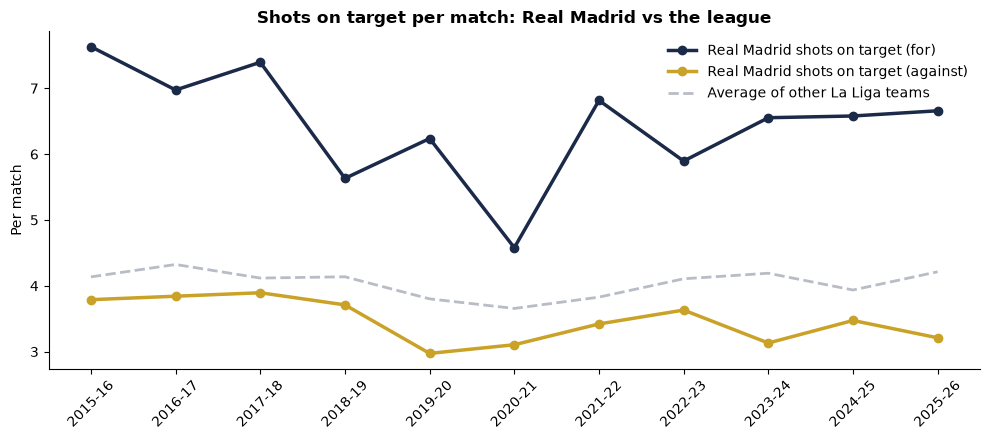

,sot,sot_ag
Season,,
2015-16,7.63,3.79
2016-17,6.97,3.84
2017-18,7.39,3.89
2018-19,5.63,3.71
2019-20,6.24,2.97
2020-21,4.58,3.11
2021-22,6.82,3.42
2022-23,5.89,3.63
2023-24,6.55,3.13


In [7]:
by_season = everyone[everyone.is_rm].groupby("Season").agg(sot=("sot", "mean"), sot_ag=("sot_ag", "mean"))
league_avg = everyone[~everyone.is_rm].groupby("Season").sot.mean()

fig, ax = plt.subplots()
ax.plot(by_season.index, by_season.sot, marker="o", color=NAVY, lw=2.5, label="Real Madrid shots on target (for)")
ax.plot(by_season.index, by_season.sot_ag, marker="o", color=GOLD, lw=2.5, label="Real Madrid shots on target (against)")
ax.plot(league_avg.index, league_avg.values, ls="--", color=GREY, lw=2, label="Average of other La Liga teams")
ax.set_ylabel("Per match")
ax.set_title("Shots on target per match: Real Madrid vs the league")
ax.legend(frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/shots_on_target_trend.svg")
plt.show()
by_season.round(2)

Real Madrid creates far more than a typical La Liga side and allows less:

- **16.7 shots and 6.5 shots on target per match**, against 11.6 and 4.0 for the rest of the league. That is about 60% more shots on target.
- They allow **10.4 shots per match**, compared with 12.0 for other teams.
- They are also a little more clinical: **0.336 goals per shot on target**, compared with 0.314 for everyone else.

The trend chart shows that the gap held up over 11 seasons. Real Madrid's shots on target dipped to 4.6 per match in 2020-21, a season played mostly without fans, but it was still above the league average. Shots on target **against** fell from about 3.8 per match in the early seasons to about 3.1 to 3.5 recently, which matches the drop in goals conceded.

## 4. What separates wins from non-wins?

I fit a logistic regression for **win (1) vs draw or loss (0)** across Real Madrid's 418 matches, using in-game statistics expressed as differences against the opponent. This model is **explanatory**: these statistics are only known after the match, so it describes what winning performances look like rather than forecasting results.

In [8]:
rm["sot_diff"] = rm.sot - rm.sot_ag
rm["shots_off_diff"] = (rm.shots - rm.sot) - (rm.shots_ag - rm.sot_ag)
rm["corner_diff"] = rm.corners - rm.corners_ag
rm["red_diff"] = rm.reds - rm.reds_opp

logit = smf.logit("win ~ sot_diff + shots_off_diff + corner_diff + red_diff + home", data=rm).fit(disp=0)
print(logit.summary2().tables[1].round(3))
odds = np.exp(logit.params).round(3)
print("\nOdds ratios:\n", odds.to_string())
print("\nMcFadden pseudo R-squared:", round(logit.prsquared, 3))

                Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept       0.133     0.182  0.729  0.466  -0.224   0.490
sot_diff        0.341     0.047  7.269  0.000   0.249   0.433
shots_off_diff -0.123     0.029 -4.301  0.000  -0.179  -0.067
corner_diff    -0.093     0.038 -2.460  0.014  -0.167  -0.019
red_diff       -0.914     0.298 -3.071  0.002  -1.498  -0.331
home            0.919     0.267  3.447  0.001   0.396   1.441

Odds ratios:
 Intercept         1.142
sot_diff          1.406
shots_off_diff    0.884
corner_diff       0.911
red_diff          0.401
home              2.506

McFadden pseudo R-squared: 0.235


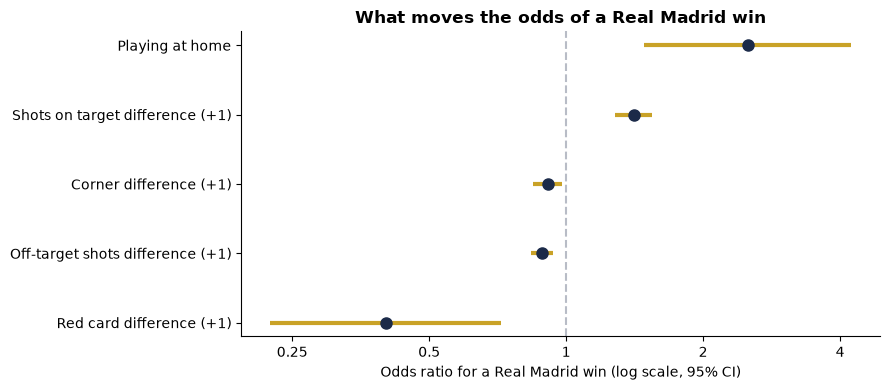

In [9]:
ci = np.exp(logit.conf_int().drop("Intercept"))
orr = np.exp(logit.params.drop("Intercept"))
labels = {"sot_diff": "Shots on target difference (+1)", "shots_off_diff": "Off-target shots difference (+1)",
          "corner_diff": "Corner difference (+1)", "red_diff": "Red card difference (+1)", "home": "Playing at home"}
order = orr.sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(orr[order], range(len(order)), xerr=[orr[order] - ci.loc[order, 0], ci.loc[order, 1] - orr[order]],
            fmt="o", color=NAVY, ecolor=GOLD, elinewidth=3, capsize=0, ms=8)
ax.axvline(1, color=GREY, ls="--")
ax.set_yticks(range(len(order)), [labels[k] for k in order])
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.minorticks_off()
ax.set_xlabel("Odds ratio for a Real Madrid win (log scale, 95% CI)")
ax.set_title("What moves the odds of a Real Madrid win")
plt.tight_layout()
plt.savefig("images/win_odds_ratios.svg")
plt.show()

The model explains a fair share of the variation in results (McFadden pseudo R² = 0.235, which is reasonably strong for match-level sports data). Every predictor is significant at the 5% level.

- **Shots on target is the strongest driver.** Each extra shot on target relative to the opponent multiplies the odds of a win by about **1.41**, a 41% increase, holding the other variables fixed.
- **Playing at home multiplies the odds of winning by about 2.5**, even after accounting for the shot and corner differences. Part of home advantage is not captured by these statistics.
- **A red card difference of +1 cuts the odds of winning by about 60%** (odds ratio 0.40).
- **More off-target shots and more corners *lower* the odds of winning** (odds ratios 0.88 and 0.91), once shots on target are held fixed. This looks surprising, but it is a well-known pattern called *game state*: when Real Madrid is losing or drawing, it pushes forward and piles up low-quality shots and corners. When it is winning comfortably, it slows the game down. So these variables partly reflect the score, not just the quality of play. The lesson is that **shot quality matters more than shot volume**.

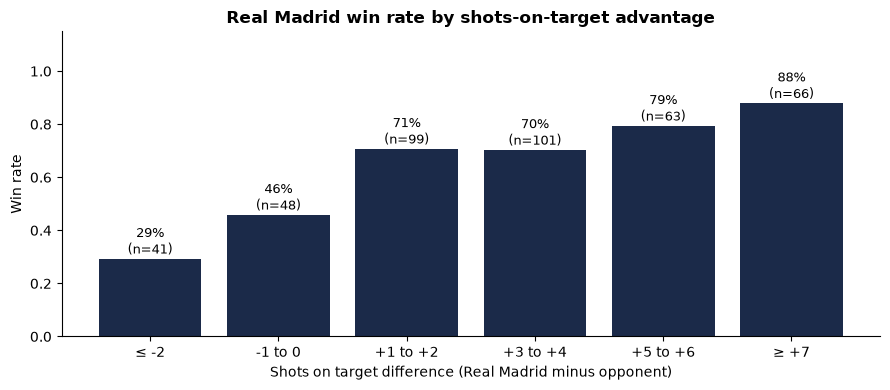

,matches,win_rate
sot_diff_band,,
≤ -2,41,0.293
-1 to 0,48,0.458
+1 to +2,99,0.707
+3 to +4,101,0.703
+5 to +6,63,0.794
≥ +7,66,0.879


In [10]:
rm["sot_diff_band"] = pd.cut(rm.sot_diff, [-20, -2, 0, 2, 4, 6, 30],
                             labels=["≤ -2", "-1 to 0", "+1 to +2", "+3 to +4", "+5 to +6", "≥ +7"])
band = rm.groupby("sot_diff_band", observed=True).agg(matches=("win", "size"), win_rate=("win", "mean"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(band.index.astype(str), band.win_rate, color=NAVY)
for i, (m, w) in enumerate(zip(band.matches, band.win_rate)):
    ax.text(i, w + 0.02, f"{w:.0%}\n(n={m})", ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_xlabel("Shots on target difference (Real Madrid minus opponent)")
ax.set_ylabel("Win rate")
ax.set_title("Real Madrid win rate by shots-on-target advantage")
plt.tight_layout()
plt.savefig("images/win_rate_by_sot_diff.svg")
plt.show()
band.round(3)

The relationship between shots-on-target advantage and winning is steep and close to steady:

- When Real Madrid had **2 or more fewer** shots on target than the opponent, it won only **29%** of the time (41 matches).
- At level to -1, it won **46%** of the time.
- With a **+1 to +4** edge it won about **70%** of the time, rising to **79%** at +5 to +6 and **88%** at +7 or more.

Even a big advantage does not guarantee a win: in 66 matches with at least 7 more shots on target, Real Madrid still failed to win 8 of them. This is the randomness that makes football hard to predict.

## 5. Do bookmakers price Real Madrid correctly?

Bet365's pre-match odds imply a probability for each outcome. Bookmakers build in a margin, so the three raw implied probabilities add up to slightly more than 1. I remove the margin by normalizing them to sum to 1. From these I get the market's **expected points** for each match, `3 × P(win) + 1 × P(draw)`, and compare them with the points Real Madrid actually earned.

In [11]:
raw = 1 / rm[["odds_win", "odds_draw", "odds_loss"]]
rm["margin"] = raw.sum(axis=1) - 1
probs = raw.div(raw.sum(axis=1), axis=0)
rm["p_win"], rm["p_draw"], rm["p_loss"] = probs.odds_win, probs.odds_draw, probs.odds_loss
rm["exp_points"] = 3 * rm.p_win + rm.p_draw
print("average bookmaker margin:", round(rm.margin.mean(), 3))

market = rm.groupby("Season").agg(actual_points=("points", "sum"), expected_points=("exp_points", "sum"),
                                  avg_win_prob=("p_win", "mean"), actual_win_rate=("win", "mean"))
market["over_under"] = market.actual_points - market.expected_points
market.round(2)

average bookmaker margin: 0.054


,actual_points,expected_points,avg_win_prob,actual_win_rate,over_under
Season,,,,,
2015-16,90,86.88,0.71,0.74,3.12
2016-17,93,88.12,0.72,0.76,4.88
2017-18,76,86.64,0.71,0.58,-10.64
2018-19,68,79.27,0.63,0.55,-11.27
2019-20,87,78.69,0.62,0.68,8.31
2020-21,84,77.14,0.61,0.66,6.86
2021-22,86,75.34,0.59,0.68,10.66
2022-23,78,76.81,0.60,0.63,1.19
2023-24,95,78.78,0.62,0.76,16.22


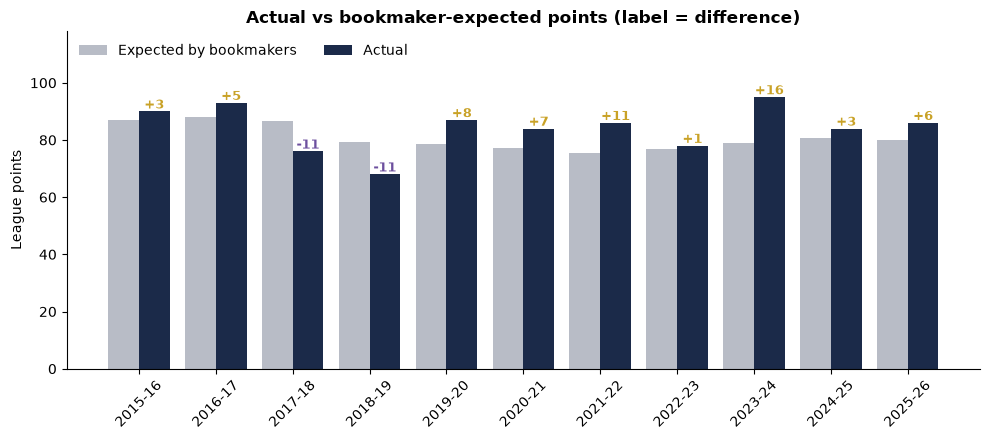

In [12]:
fig, ax = plt.subplots()
x = np.arange(len(market))
ax.bar(x - 0.2, market.expected_points, 0.4, color=GREY, label="Expected by bookmakers")
ax.bar(x + 0.2, market.actual_points, 0.4, color=NAVY, label="Actual")
for i, d in enumerate(market.over_under):
    ax.text(i + 0.2, market.actual_points.iloc[i] + 1, f"{d:+.0f}", ha="center", fontsize=9,
            color=GOLD if d > 0 else PURPLE, fontweight="bold")
ax.set_xticks(x, market.index, rotation=45)
ax.set_ylim(0, 118)
ax.set_ylabel("League points")
ax.set_title("Actual vs bookmaker-expected points (label = difference)")
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout()
plt.savefig("images/actual_vs_expected_points.svg")
plt.show()

After removing the bookmaker's built-in margin (about 5.4% on average), Real Madrid **beat the market's expected points in 9 of 11 seasons**, by about **+39 points in total**, or about 3.5 points per season.

- The biggest outperformance was **2023-24**: the market expected about 79 points and Real Madrid earned 95 (**+16**).
- The two seasons where they fell short were **2017-18 (-11)** and **2018-19 (-11)**, the same stretch where the team declined after three straight Champions League titles and Ronaldo's departure.
- Bookmakers' average pre-match win probability fell from about 0.71 in 2015-17 to about 0.59 to 0.64 from 2019-20 on, yet Real Madrid's real win rate stayed between 0.63 and 0.76 in those seasons.

One reading is that the market has been slightly too cautious about Real Madrid since 2019-20. A second reading is that a few seasons of good luck add up. With only 38 matches per season, a 6 to 10 point gap can happen by chance, so this is a pattern worth noting, not proof that the odds are systematically wrong.

### Can a simple pre-match model beat the market?

As a test, I train a pre-match model using only information available **before kickoff**: home or away, and Real Madrid's form (points per game over the previous 5 league matches, and goal difference over the previous 5). I train on 2015-16 to 2022-23 and test on the three most recent seasons, 2023-24 to 2025-26, then compare it with the bookmaker's win probability on the same test matches.

In [13]:
rm["form_ppg5"] = rm.points.shift(1).rolling(5, min_periods=3).mean()
rm["form_gd5"] = (rm.gf - rm.ga).shift(1).rolling(5, min_periods=3).mean()
model_df = rm.dropna(subset=["form_ppg5", "form_gd5"]).copy()
test_seasons = ["2023-24", "2024-25", "2025-26"]
train = model_df[~model_df.Season.isin(test_seasons)]
test = model_df[model_df.Season.isin(test_seasons)]
feats = ["home", "form_ppg5", "form_gd5"]

clf = LogisticRegression().fit(train[feats], train.win)
test = test.assign(p_model=clf.predict_proba(test[feats])[:, 1])

summary = pd.DataFrame({
    "AUC": [roc_auc_score(test.win, test.p_model), roc_auc_score(test.win, test.p_win)],
    "Brier score (lower is better)": [brier_score_loss(test.win, test.p_model), brier_score_loss(test.win, test.p_win)],
}, index=["Form + home model", "Bookmaker (Bet365)"])
print(f"train matches: {len(train)}, test matches: {len(test)}, test win rate: {test.win.mean():.3f}")
summary.round(3)

train matches: 301, test matches: 114, test win rate: 0.719


,AUC,Brier score (lower is better)
Form + home model,0.652,0.197
Bookmaker (Bet365),0.694,0.190


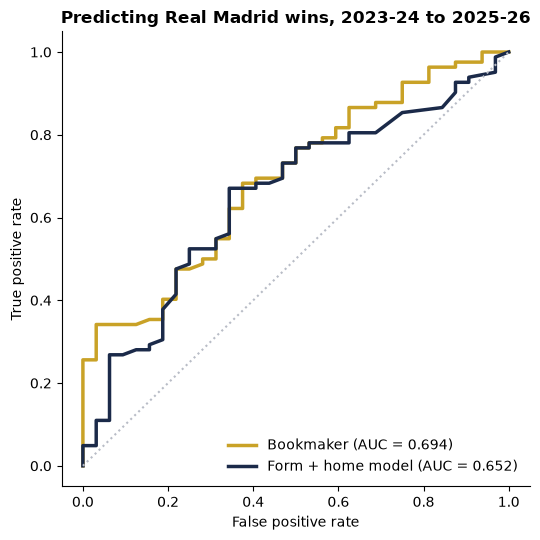

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, name, col in [(test.p_win, "Bookmaker", GOLD), (test.p_model, "Form + home model", NAVY)]:
    fpr, tpr, _ = roc_curve(test.win, p)
    ax.plot(fpr, tpr, lw=2.5, color=col, label=f"{name} (AUC = {roc_auc_score(test.win, p):.3f})")
ax.plot([0, 1], [0, 1], ls=":", color=GREY)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Predicting Real Madrid wins, 2023-24 to 2025-26")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("images/roc_model_vs_market.svg")
plt.show()

On the 114 test matches from the last three seasons, the bookmaker beats my simple model, as expected:

| | AUC | Brier score |
|---|---:|---:|
| Form + home model | 0.652 | 0.197 |
| Bookmaker (Bet365) | **0.694** | **0.190** |

Both are better than guessing (AUC 0.5), but neither is very strong. Real Madrid wins about 72% of the time, so the hard part is spotting the rare draws and losses. The bookmaker has information my model does not: opponent strength, injuries, rotation before European matches, and the betting market itself. Adding opponent ratings, expected goals (xG) and rest days would be the natural next step.

## 6. Conclusions


1. **Consistency:** over 11 seasons, Real Madrid won 4 league titles, never finished below 3rd, and averaged 2.22 points per game. The 2023-24 season (95 points, 1 loss) stands out.
2. **Home advantage is real and large:** 75% win rate at home vs 60% away, and playing at home multiplies the odds of winning by about 2.5 even after controlling for shots.
3. **Shot quality beats shot volume:** each extra shot on target relative to the opponent raises the odds of a win by about 41%. Extra off-target shots and corners do not help, partly because they pile up when the team is chasing a game.
4. **The market has underrated Real Madrid lately:** they beat bookmaker-expected points in 9 of 11 seasons, by about 39 points in total. Still, the bookmaker's pre-match probabilities predict individual wins better than a simple form-based model.

**Limitations:** the data has no expected goals (xG), possession, lineups or injuries, and it covers league matches only (no Champions League or Copa del Rey). The win model uses statistics recorded after the match, so it explains wins rather than forecasting them.